# RV3D — Training and Evaluation

Level-set PINN for the **3D reversed single vortex** (Enright et al. 2002
deformation field). A sphere of radius 0.15 centred at (0.35, 0.35, 0.35) is
stretched into a thin folded sheet and returned to its initial shape:

    u =  2 sin^2(pi x) sin(2 pi y) sin(2 pi z) cos(pi tau)
    v =   -sin(2 pi x) sin^2(pi y) sin(2 pi z) cos(pi tau)
    w =   -sin(2 pi x) sin(2 pi y) sin^2(pi z) cos(pi tau)

with tau = t/T. The `cos(pi tau)` factor integrates to zero over [0,1], so the
flow reverses at tau = 1/2 and the sphere reforms at t = T.

**Why this benchmark is different from the other three.** Translation, rotation
and Zalesak are all *rigid* motions: the exact solution stays an exact signed
distance function, so the eikonal term is free supervision that never conflicts
with the transport residual. Here the interface stretches, the advected field
stops being an SDF, and enforcing |grad phi| = 1 genuinely competes with the
PDE. This is the regime where the eikonal weight actually matters.

**No closed-form solution.** Since phi is advected as a passive scalar,
phi(x, tau) = phi_0(X(0; x, tau)) along backward characteristics. The velocity
is analytic, so the reference is obtained by RK4 back-tracing — accurate to the
integrator error, which at T = 2 with 200 steps is ~2e-7 in max norm, orders
below the network error. The reference is network-independent, so it is
computed once and cached to `.npz`.

**Divergence free** (2 pi - pi - pi = 0), so the enclosed volume is exactly
constant and `vol_MAPE` stays meaningful at every snapshot.

**Outputs:** metrics table, `rv3d_interface.pdf`, `rv3d_verification.pdf`,
`rv3d_growth.pdf`, `rv3d_loss_history.pdf`, and one row appended to `RV3D_results.csv`.

Definitions live in `rv3d_core.py`, shared with `01_eikonal_ablation.ipynb`.

In [1]:
# --- setup -------------------------------------------------------------
# Put rv3d_core.py in the same Drive folder as this notebook.
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/RV3D'
except ImportError:
    PROJECT_DIR = os.getcwd()

sys.path.insert(0, PROJECT_DIR)
os.makedirs(PROJECT_DIR, exist_ok=True)

import numpy as np
import torch
import rv3d_core as core

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device,
      '|', torch.cuda.get_device_name(0) if device == 'cuda' else '')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | Tesla T4


## Configuration

Everything tunable lives here. `W_EIK` is the value selected by
`01_eikonal_ablation.ipynb`.

In [2]:
# --- configuration -----------------------------------------------------
W_EIK        = 0.00001          # <-- selected by the ablation notebook
W_PDE, W_IC  = 1.0, 10.0

SEED         = 42
N_F, N_I     = 10000, 5000
LAYERS, NEURONS = 8, 256
T_FINAL      = 2.0
ADAM_EPOCHS  = 20000
LBFGS_EPOCHS = 2000
GRID_N       = 201
N_SNAPSHOTS  = 6
RK4_STEPS    = 200          # reference back-tracing; max error ~2e-7 at T=2

M_CHUNKS, EPS_CAUSAL = 10, 1.0
RAD_FREQ, RAD_CANDIDATES, RAD_K, RAD_C = 1000, 20000, 1.0, 1.0
RAR_FREQ, RAR_CANDIDATES, RAR_ADD      = 1800, 50000, 500

CKPT     = f'{PROJECT_DIR}/RV3D_weik{W_EIK:g}_seed{SEED}.pth'
PRETRAIN = f'{PROJECT_DIR}/RV3D_pretrained.pth'
CSV_PATH = f'{PROJECT_DIR}/RV3D_results.csv'
REF_CACHE = f'{PROJECT_DIR}/RV3D_reference_n{GRID_N}_T{T_FINAL:g}.npz'
FIGDIR   = PROJECT_DIR

times, tlabels = core.snapshot_times(T_FINAL, N_SNAPSHOTS)
print('snapshots:', [f'{t:.2f}' for t in times])

snapshots: ['0.00', '0.40', '0.80', '1.20', '1.60', '2.00']


## Train (skipped if a checkpoint exists)

In [3]:
# --- train or load -----------------------------------------------------
model = core.build_model(device, seed=SEED, layers=LAYERS, neurons=NEURONS)

load_from = PRETRAIN if os.path.exists(PRETRAIN) else (CKPT if os.path.exists(CKPT) else None)

if load_from:
    ck = torch.load(load_from, map_location=device, weights_only=False)
    model.load_state_dict(ck['model_state_dict'])
    print(f'loaded {os.path.basename(load_from)} — training skipped')
    print(f"  trained with w_eik={ck.get('w_eik', '?')}, "
          f"seed={ck.get('seed', '?')}, time={ck.get('minutes', float('nan')):.1f} min")
else:
    X_f, X_i = core.sample_points(N_F, N_I, device, seed=SEED)
    sampler = core.AdaptiveSampler(model, X_f, T_FINAL, device,
                                   rad_freq=RAD_FREQ, rad_candidates=RAD_CANDIDATES,
                                   rad_k=RAD_K, rad_c=RAD_C,
                                   rar_freq=RAR_FREQ, rar_candidates=RAR_CANDIDATES,
                                   rar_add=RAR_ADD)
    loss_fn = core.make_loss(model, sampler, X_i, T_FINAL, W_PDE, W_IC, W_EIK,
                             m_chunks=M_CHUNKS, eps_causal=EPS_CAUSAL)
    ck = core.train(model, loss_fn, sampler=sampler, adam_epochs=ADAM_EPOCHS,
                    lbfgs_epochs=LBFGS_EPOCHS)
    ck.update(model_state_dict=model.state_dict(), w_eik=W_EIK, seed=SEED,
              w_pde=W_PDE, w_ic=W_IC, N_f=N_F, N_i=N_I,
              layers=LAYERS, neurons=NEURONS, m_chunks=M_CHUNKS,
              eps_causal=EPS_CAUSAL, adam_epochs=ADAM_EPOCHS,
              lbfgs_epochs=LBFGS_EPOCHS)
    torch.save(ck, CKPT)
    print('saved', CKPT)

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Adam      0 | total 2.222e+00 | pde 7.046e-02 | ic 2.152e-01 | eik 9.222e-01 | lr 1.000e-03 | pts 10000
Adam   2000 | total 3.126e-02 | pde 1.618e-02 | ic 1.508e-03 | eik 1.412e-01 | lr 9.757e-04 | pts 10500
Adam   4000 | total 4.405e-02 | pde 3.047e-02 | ic 1.358e-03 | eik 3.225e-01 | lr 9.054e-04 | pts 11000
Adam   6000 | total 1.839e-02 | pde 1.306e-02 | ic 5.322e-04 | eik 4.357e-01 | lr 7.959e-04 | pts 11500
Adam   8000 | total 4.471e-03 | pde 3.378e-03 | ic 1.085e-04 | eik 8.280e-01 | lr 6.579e-04 | pts 12000
Adam  10000 | total 2.467e-03 | pde 1.948e-03 | ic 5.068e-05 | eik 1.270e+00 | lr 5.049e-04 | pts 12500
Adam  12000 | total 1.722e-03 | pde 1.342e-03 | ic 3.622e-05 | eik 1.746e+00 | lr 3.520e-04 | pts 13000
Adam  14000 | total 1.143e-03 | pde 9.499e-04 | ic 1.717e-05 | eik 2.092e+00 | lr 2.140e-04 | pts 13500
Adam  16000 | total 8.770e-04 | pde 7.233e-04 | ic 1.324e-05 | eik 2.130e+00 | lr 1.045e-04 | pts 14000
Adam  18000 | total 9.177e-04 | pde 7.734e-04 | ic 1.190e-05 | e

## Evaluate

Metrics on a 201³ grid at six snapshots.

- `abs L2` — sqrt(mean(e²)); equals the discrete L² norm since the domain has unit measure
- `rel L2` — standard relative-L₂ PINN convention
- `MAPE` — volume conservation error, V by cell counting
- `eik dev` — mean ‖∇φ̂|−1| in a 3-cell band around the interface

In [4]:
# --- reference fields, then evaluate -----------------------------------
grid = core.Grid(n=GRID_N)

# network-independent: computed once, cached, reused by the ablation notebook
PHI_E = core.reference_fields(grid, times, T_FINAL, device,
                              nsteps=RK4_STEPS, cache_path=REF_CACHE)

res = core.evaluate(model, grid, times, T_FINAL, device, PHI_E, cache=True)
core.print_metrics(times, res)

loaded reference fields from RV3D_reference_n201_T2.npz

Snapshot          abs L2   rel L2 (%)      vol abs    MAPE (%)      eik dev
---------------------------------------------------------------------------
t=0.00          6.50e-04       0.152%     8.12e-05      0.574%     2.06e-02
t=0.40          1.90e-03       0.445%     1.32e-04      0.935%     5.56e-01
t=0.80          2.95e-03       0.692%     9.25e-05      0.654%     1.23e+00
t=1.20          3.32e-03       0.777%     8.23e-05      0.582%     1.20e+00
t=1.60          3.20e-03       0.750%     6.20e-05      0.438%     5.28e-01
t=2.00          3.10e-03       0.727%     2.80e-05      0.198%     4.67e-02
---------------------------------------------------------------------------
avg             2.52e-03       0.591%     7.97e-05      0.564%     5.97e-01

volume-metric noise floor (counting the reference): 0.003% – 0.081%


## Figures

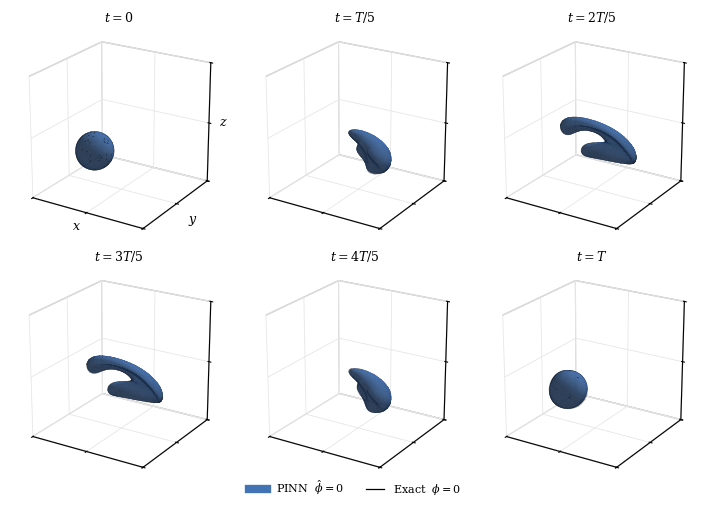

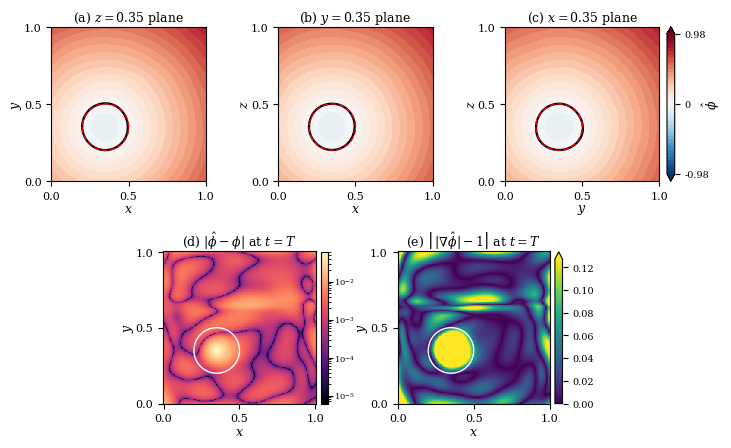

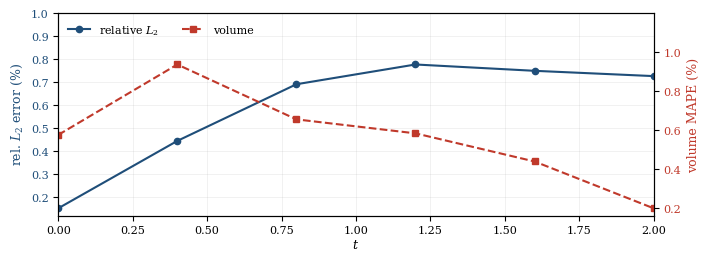

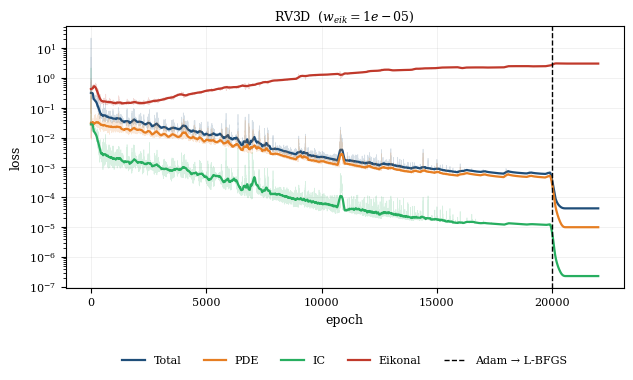

In [5]:
# --- figures -----------------------------------------------------------
import matplotlib.pyplot as plt

# On the folded sheet the exact silhouette has many branches and can read as
# speckle; set show_exact=False for a purely qualitative panel and let Fig. B
# carry the predicted-vs-exact comparison.
core.figure_interface(grid, times, tlabels, res['PHI_P'], res['PHI_E'],
                      savepath=f'{FIGDIR}/rv3d_interface', show_exact=True)
plt.show()

core.figure_verification(grid, times, res, T_FINAL,
                         savepath=f'{FIGDIR}/rv3d_verification',
                         include_growth=False)
plt.show()

core.figure_growth(times, res, savepath=f'{FIGDIR}/rv3d_growth')
plt.show()

if 'history' in ck:
    core.figure_loss_history(ck['history'], ADAM_EPOCHS,
                             rf'RV3D  ($w_{{eik}}={W_EIK:g}$)',
                             savepath=f'{FIGDIR}/rv3d_loss_history')
    plt.show()
else:
    print('no loss history in this checkpoint — rv3d_loss_history')

## Log the run

In [6]:
# --- append one row ----------------------------------------------------
import csv

row = {'w_eik': W_EIK, 'seed': SEED, 'w_pde': W_PDE, 'w_ic': W_IC,
       'N_f': N_F, 'N_i': N_I, 'layers': LAYERS, 'neurons': NEURONS,
       'adam_epochs': ADAM_EPOCHS, 'lbfgs_epochs': LBFGS_EPOCHS,
       'scheduler': 'CosineAnnealingLR', 'eta_min': 1e-5,
       'grid_n': GRID_N, 't_normalized': True}

for i, t in enumerate(times):
    tag = f't{i}'
    row[f'L2abs_{tag}']  = f"{res['l2_abs'][i]:.3e}"
    row[f'L2rel_{tag}']  = f"{res['rel_L2'][i]:.4f}"
    row[f'volabs_{tag}'] = f"{res['vol_abs'][i]:.3e}"
    row[f'MAPE_{tag}']   = f"{res['vol_MAPE'][i]:.4f}"
    row[f'eikdev_{tag}'] = f"{res['eik_dev'][i]:.3e}"

row.update({'avg_L2abs':  f"{res['avg_l2_abs']:.3e}",
            'avg_L2rel':  f"{res['avg_rel_L2']:.4f}",
            'avg_volabs': f"{res['avg_vol_abs']:.3e}",
            'avg_MAPE':   f"{res['avg_vol_MAPE']:.4f}",
            'avg_eikdev': f"{res['avg_eik_dev']:.3e}",
            'minutes':    f"{ck.get('minutes', float('nan')):.2f}",
            'lbfgs_gain': f"{ck.get('lbfgs_gain', float('nan')):.3e}"})

new = not os.path.exists(CSV_PATH) or os.path.getsize(CSV_PATH) == 0
with open(CSV_PATH, 'a', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(row))
    if new:
        w.writeheader()
    w.writerow(row)
print('row appended →', CSV_PATH)

row appended → /content/drive/MyDrive/RV3D/RV3D_results.csv
